# 01 – Exploring the match data

Before building any features or models, this notebook checks that `data/matches.csv` (made by `src/download.py`) can be trusted:
is anything missing, are team names and dates consistent across seasons, are the betting odds complete, and how often does each result happen?

The notebook only **reads** the data. Any cleaning the pipeline needs happens in `src/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# .copy() packs the 195 columns together in memory (avoids a PerformanceWarning).
matches = pd.read_csv(Path("..") / "data" / "matches.csv", low_memory=False).copy()

## 1. Data

One row per match. Each season has its own set of columns on football-data.co.uk, so the combined table has every column that appears in *any* season.

In [2]:
print(f"{len(matches)} matches, {matches.shape[1]} columns")
matches.groupby("Season").size().rename("matches").to_frame()

4240 matches, 195 columns


,matches
Season,
2015/16,380
2016/17,380
2017/18,380
2018/19,380
2019/20,380
2020/21,380
2021/22,380
2022/23,380
2023/24,380


In [3]:
matches[["Season", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR",
         "HS", "AS", "HST", "AST", "HC", "AC", "B365H", "B365D", "B365A"]].head()

,Season,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HS,AS,HST,AST,HC,AC,B365H,B365D,B365A
0,2015/16,08/08/2015,Bournemouth,Aston Villa,0,1,A,11,7,2,3,6,3,2.00,3.6,4.00
1,2015/16,08/08/2015,Chelsea,Swansea,2,2,D,11,18,3,10,4,8,1.36,5.0,11.00
2,2015/16,08/08/2015,Everton,Watford,2,2,D,10,11,5,5,8,2,1.70,3.9,5.50
3,2015/16,08/08/2015,Leicester,Sunderland,4,2,H,19,10,8,5,6,3,1.95,3.5,4.33
4,2015/16,08/08/2015,Man United,Tottenham,1,0,H,9,9,1,4,1,2,1.65,4.0,6.00


## 2. Missing values

Only the columns this project uses are checked. The other ~180 columns (other bookmakers, cards, fouls…) are irrelevant if they have gaps.

In [4]:
needed = ["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR",
          "HS", "AS", "HST", "AST", "HC", "AC", "B365H", "B365D", "B365A"]
matches[needed].isna().sum().rename("missing").to_frame()

,missing
Date,0
HomeTeam,0
AwayTeam,0
FTHG,0
FTAG,0
FTR,0
HS,0
AS,0
HST,0
AST,0


## 3. Team names

If a team were spelled two ways (e.g. "Man United" and "Man Utd"), its form would be split across two "teams". Each season should have exactly 20 names, and each name should look like a distinct club.

In [5]:
appearances = pd.concat([
    matches[["Season", "HomeTeam"]].rename(columns={"HomeTeam": "Team"}),
    matches[["Season", "AwayTeam"]].rename(columns={"AwayTeam": "Team"}),
]).drop_duplicates()

print("Teams per season:", appearances.groupby("Season").size().unique())
print("Distinct team names:", appearances["Team"].nunique())

Teams per season: [20]
Distinct team names: 35


In [6]:
# Seasons each team appears in, most to fewest.
appearances.groupby("Team")["Season"].agg(seasons="count", first="min", last="max") \
    .sort_values(["seasons", "first"], ascending=[False, True])

,seasons,first,last
Team,,,
Arsenal,12,2015/16,2026/27
Chelsea,12,2015/16,2026/27
Crystal Palace,12,2015/16,2026/27
Everton,12,2015/16,2026/27
Liverpool,12,2015/16,2026/27
Man City,12,2015/16,2026/27
Man United,12,2015/16,2026/27
Tottenham,12,2015/16,2026/27
Newcastle,11,2015/16,2026/27


## 4. Dates

Dates are stored as text, day first. 2016/17 uses a two-digit year (`13/08/16`); every other season uses four digits (`13/08/2017`).

In [7]:
matches.assign(date_length=matches["Date"].str.len()) \
    .groupby("Season")["date_length"].unique().to_frame("characters in Date")

,characters in Date
Season,
2015/16,[10]
2016/17,[8]
2017/18,[10]
2018/19,[10]
2019/20,[10]
2020/21,[10]
2021/22,[10]
2022/23,[10]
2023/24,[10]


In [8]:
# dayfirst=True: 05/08 means 5 August, not 8 May.  format="mixed": accept both year styles.
dates = pd.to_datetime(matches["Date"], dayfirst=True, format="mixed")

print("Unparsed dates:", dates.isna().sum())
matches.assign(parsed=dates).groupby("Season")["parsed"].agg(["min", "max"])

Unparsed dates: 0


,min,max
Season,,
2015/16,2015-08-08,2016-05-17
2016/17,2016-08-13,2017-05-21
2017/18,2017-08-11,2018-05-13
2018/19,2018-08-10,2019-05-12
2019/20,2019-08-09,2020-07-26
2020/21,2020-09-12,2021-05-23
2021/22,2021-08-13,2022-05-22
2022/23,2022-08-05,2023-05-28
2023/24,2023-08-11,2024-05-19


Every date parses, and each season starts in August/September and ends in May, except 2019/20, which ran to July 2020 after the COVID pause. Date conversion is done in `src/features.py`, because a CSV can't store a date type.

## 5. Odds

The bookmaker baseline needs one set of odds that exists in every season. Bet365 (`B365H/D/A`) does. The market-average columns changed name in 2019/20 (`BbAvH` → `AvgH`), so they would need merging first.

In [9]:
odds_columns = ["B365H", "BbAvH", "AvgH", "PSH"]
matches.groupby("Season")[odds_columns].apply(lambda season: season.notna().mean()) \
    .map("{:.0%}".format)

,B365H,BbAvH,AvgH,PSH
Season,,,,
2015/16,100%,100%,0%,100%
2016/17,100%,100%,0%,100%
2017/18,100%,100%,0%,100%
2018/19,100%,100%,0%,100%
2019/20,100%,0%,100%,100%
2020/21,100%,0%,100%,100%
2021/22,100%,0%,100%,100%
2022/23,100%,0%,100%,100%
2023/24,100%,0%,100%,100%


Bet365 is 100% complete in every season, so the baseline uses `B365H/D/A`. (Pinnacle, `PSH`, disappears partway through 2025/26.)

## 6. Results

`FTR` is what the models predict: **H** home win, **D** draw, **A** away win.

In [10]:
matches["FTR"].value_counts(normalize=True).reindex(["H", "D", "A"]) \
    .map("{:.1%}".format).to_frame("share of matches")

,share of matches
FTR,
H,44.2%
D,23.8%
A,32.0%


In [11]:
by_season = pd.crosstab(matches["Season"], matches["FTR"], normalize="index")[["H", "D", "A"]]
by_season.map("{:.1%}".format)

FTR,H,D,A
Season,,,
2015/16,41.3%,28.2%,30.5%
2016/17,49.2%,22.1%,28.7%
2017/18,45.5%,26.1%,28.4%
2018/19,47.6%,18.7%,33.7%
2019/20,45.3%,24.2%,30.5%
2020/21,37.9%,21.8%,40.3%
2021/22,42.9%,23.2%,33.9%
2022/23,48.4%,22.9%,28.7%
2023/24,46.1%,21.6%,32.4%


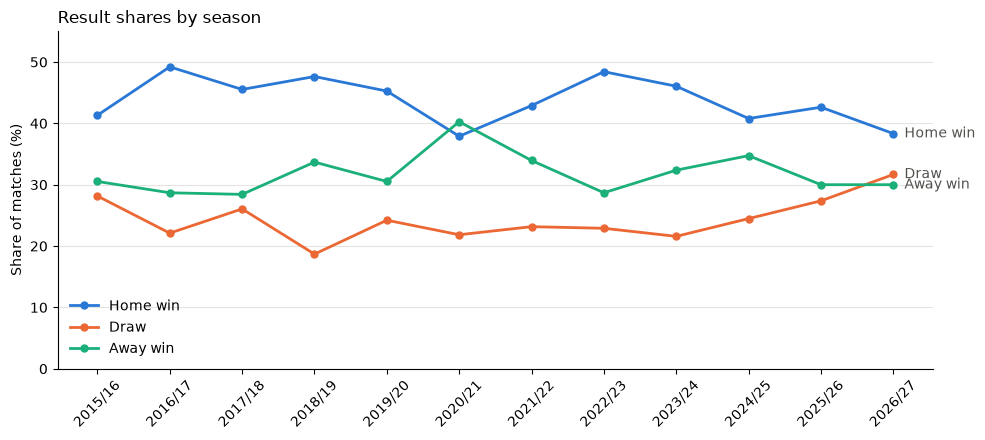

In [12]:
colours = {"H": "#2a78d6", "D": "#eb6834", "A": "#1baf7a"}
names = {"H": "Home win", "D": "Draw", "A": "Away win"}

fig, ax = plt.subplots(figsize=(10, 4.5))
for result in ["H", "D", "A"]:
    share = by_season[result] * 100
    ax.plot(share.index, share.values, color=colours[result], linewidth=2,
            marker="o", markersize=5, label=names[result])
    ax.annotate(names[result], (share.index[-1], share.values[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color="#52514e")

ax.set_ylabel("Share of matches (%)")
ax.set_ylim(0, 55)
ax.set_title("Result shares by season", loc="left")
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

Two seasons stand out:

- **2020/21**, played without crowds, is the only season where away wins (40.3%) beat home wins (37.9%), which fits the idea that home advantage is partly the crowd.
- **2025/26** is the test season. Home wins were 42.6%, so a model that always predicts "home win" would score **42.6%** accuracy there. That is the first baseline to beat.

(2026/27 has only ~60 matches so far, so its shares will move a lot.)

## Takeaways

- **No cleaning needed** for the columns this project uses: nothing is missing and team names are consistent.
- **Dates** must be parsed with `dayfirst=True, format="mixed"` in `src/features.py` before sorting matches by time.
- **Bookmaker baseline** uses Bet365 odds (`B365H/D/A`), the only full set with the same name in every season.
- **Draws are ~24% of matches.** Models usually struggle to predict them, which is worth watching in the confusion matrix later.